# SpectralCubePlus: noise, emission masks, and moment maps

This example uses the bundled `CloudH_HCN.fits` cube to estimate noise and measure emission. First we build a mask **without smoothing**. Then we build a mask **with spatial smoothing** and compare the results. In both cases, moment maps are measured from the original-resolution data.

Run the cells in order with the current checkout installed (`python -m pip install -e .` from the repository root). The input path works when the notebook starts in either `examples` or the repository root. Mask thresholds are illustrative and should be chosen for your science data.

## 1. Import the module and find the input cube

`SpectralCubePlus` provides the RMS, masking, and uncertainty methods. Astropy supplies physical units; NumPy and Matplotlib are used for the comparison plot.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from spectral_cube import Projection
from spectral_cube_plus import SpectralCubePlus
from spectral_cube_plus.spectralcubeplus_moments import get_momentmaps

example_dir = Path.cwd() if (Path.cwd() / "data/CloudH_HCN.fits").is_file() else Path.cwd() / "examples"
cube_path = example_dir / "data/CloudH_HCN.fits"

/opt/homebrew/Caskroom/miniforge/base/envs/astro/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Read the cube and prepare its units

The bundled cube already has a velocity axis and a common beam. Express velocity in km/s and brightness temperature in K before estimating RMS. For a frequency-axis cube, `with_spectral_unit` also needs the line rest frequency and velocity convention. The printed shape is in `(spectral, y, x)` order.

In [2]:
cube_plus = SpectralCubePlus.read(cube_path)
cube_plus = cube_plus.with_spectral_unit(u.km / u.s).to(u.K)

print("Input:", cube_path)
print("Shape:", cube_plus.shape)
print("Units:", cube_plus.unit, cube_plus.spectral_axis.unit)
print("Original beam:", cube_plus.beam)

Input: /Users/abarnes/Library/CloudStorage/Dropbox/GitHub/spectral_cube_plus/examples/data/CloudH_HCN.fits
Shape: (4000, 21, 16)
Units: K km / s
Original beam: Beam: BMAJ=29.256613717733998 arcsec BMIN=29.256613717733998 arcsec BPA=0.0 deg


## 3. Estimate native-resolution noise

`get_rms_auto()` estimates one RMS value per spatial sightline using robust spectral clipping and stores the map in `cube_plus.rms` and `cube_plus.rms_hdu`. Estimate noise before applying an emission mask. If you know suitable line-free intervals, use `get_rms()` instead. This native RMS will also supply the uncertainties when we later use a smoothed detection mask.

In [3]:
rms = cube_plus.get_rms_auto()
print("Median native RMS:", np.nanmedian(rms))

Median native RMS: 0.03082534298300743 K


## 4. Build an emission mask without smoothing

Use the stored native RMS to find seeds above `hthresh = 10` and grow them into connected emission above `lthresh = 5`, both in RMS multiples. The default neighbouring-channel check, gap closing, and minimum spatial area cut also apply. `True` in the returned array means included emission.

`cube_plus.masked` contains the emission-selected cube. Keep it in a separate variable because another `get_expmask()` call replaces this attribute.

In [4]:
mask_options = dict(hthresh=10, lthresh=5)

mask_native = cube_plus.get_expmask(**mask_options)
masked_native = cube_plus.masked
print("Included samples without smoothing:", np.count_nonzero(mask_native))

Using stored native RMS: median=0.0308253, range=[0.024233, 0.124234] K.
Included samples without smoothing: 29778


## 5. Measure moments without smoothing

Request integrated intensity, centroid, dispersion, their statistical uncertainties, and moment/error ratios with `get_momentmaps(..., velomoms=True)`. The `sigma` product is the dispersion, not the squared second moment; we keep the historical variable and filename `mom2` for it. Use native RMS and the finite channels in the native emission mask.

Centroid and dispersion errors use first-order propagation of independent channel noise, conditional on a fixed mask. They exclude channel covariance, mask-selection uncertainty, calibration uncertainty, and uncertainty in RMS. Weak or nearly cancelling spectra can make this approximation unreliable. Empty sightlines have NaN errors, zero dispersion has NaN linewidth error, and zero-error ratios are NaN. The signed `mom1s2n = mom1 / mom1err` depends on the velocity zero point and is not emission-detection significance.


In [5]:
maps_native = get_momentmaps(masked_native, cube_plus.rms_hdu, velomoms=True)
mom0 = Projection.from_hdu(maps_native["mom0"])
mom0err = Projection.from_hdu(maps_native["mom0err"])
mom1 = Projection.from_hdu(maps_native["mom1"])
mom2 = Projection.from_hdu(maps_native["sigma"])
mom1err = Projection.from_hdu(maps_native["mom1err"])
sigmaerr = Projection.from_hdu(maps_native["sigmaerr"])
mom1s2n = Projection.from_hdu(maps_native["mom1s2n"])
sigmas2n = Projection.from_hdu(maps_native["sigmas2n"])


/opt/homebrew/Caskroom/miniforge/base/envs/astro/lib/python3.13/site-packages/spectral_cube/_moments.py:182: RuntimeWarning: invalid value encountered in divide
  return (np.nansum(data * pix_cen, axis=axis) /


## 6. Build an emission mask with spatial smoothing

`smooth_factor = 2` doubles both beam FWHM axes and preserves the position angle. The spatial pixel grid and spectral axis stay the same. The method estimates fresh RMS on this detection cube and applies the same threshold settings there; closing and area cuts also use the larger detection beam.

The resulting mask is applied to the original-resolution data. `cube_plus.mask_cube` exposes the smoothed detection cube and its RMS, while `cube_plus.masked` retains the original intensities and beam. Native RMS remains the uncertainty reference. Do not pass an explicit `rms=` together with `smooth_factor`.

In [6]:
mask_smooth = cube_plus.get_expmask(smooth_factor=2, **mask_options)
masked_smooth = cube_plus.masked
smoothed_detection = cube_plus.mask_cube

print("Detection beam:", smoothed_detection.beam)
print("Measurement beam:", masked_smooth.beam)
print("Median detection RMS:", np.nanmedian(smoothed_detection.rms))
print("Median native RMS:", np.nanmedian(cube_plus.rms))
print("Included samples with smoothing:", np.count_nonzero(mask_smooth))

Using stored native RMS: median=0.0308253, range=[0.024233, 0.124234] K.
Retaining native RMS for uncertainties; determining a new smoothed RMS automatically with get_rms_auto().
Smoothed detection RMS: median=0.0160939, range=[0.00995297, 0.0380914] K.
Detection beam: Beam: BMAJ=58.513227435467996 arcsec BMIN=58.513227435467996 arcsec BPA=0.0 deg
Measurement beam: Beam: BMAJ=29.256613717733998 arcsec BMIN=29.256613717733998 arcsec BPA=0.0 deg
Median detection RMS: 0.016093922975965628 K
Median native RMS: 0.03082534298300743 K
Included samples with smoothing: 48126


## 7. Measure moments using the smoothed detection mask

These measurements still use the native-resolution cube and native RMS. Smoothing changes which samples enter the calculation, rather than smoothing the moment maps. Request the same complete set of products with the new mask. The first-order errors condition on this fixed mask and do not include uncertainty from detecting or selecting emission.


In [7]:
maps_smooth = get_momentmaps(masked_smooth, cube_plus.rms_hdu, velomoms=True)
mom0_smooth = Projection.from_hdu(maps_smooth["mom0"])
mom0err_smooth = Projection.from_hdu(maps_smooth["mom0err"])
mom1_smooth = Projection.from_hdu(maps_smooth["mom1"])
mom2_smooth = Projection.from_hdu(maps_smooth["sigma"])
mom1err_smooth = Projection.from_hdu(maps_smooth["mom1err"])
sigmaerr_smooth = Projection.from_hdu(maps_smooth["sigmaerr"])
mom1s2n_smooth = Projection.from_hdu(maps_smooth["mom1s2n"])
sigmas2n_smooth = Projection.from_hdu(maps_smooth["sigmas2n"])


/opt/homebrew/Caskroom/miniforge/base/envs/astro/lib/python3.13/site-packages/spectral_cube/_moments.py:182: RuntimeWarning: invalid value encountered in divide
  return (np.nansum(data * pix_cen, axis=axis) /


## 8. Compare the integrated-intensity maps

The two panels use the same intensity scale and native spatial grid. Differences reflect the mask selection, including the beam-dependent closing and area cuts. A smoothed detection mask can help select extended emission, but need not include every sample selected without smoothing.

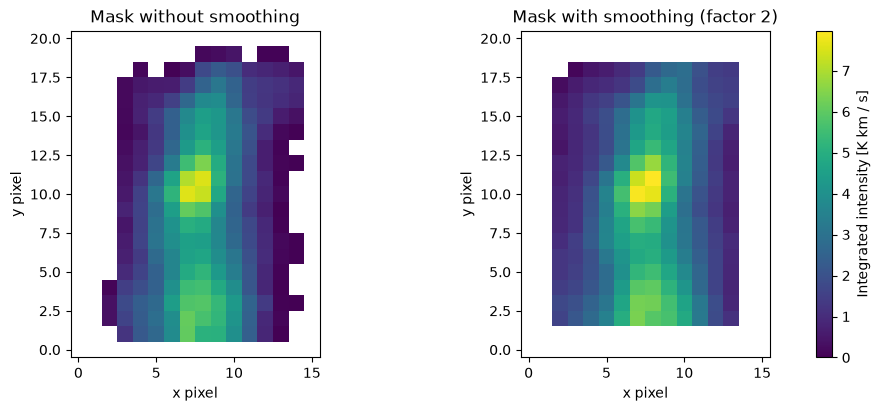

In [8]:
vmax = np.nanmax([mom0.value, mom0_smooth.value])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, moment, title in zip(
    axes, [mom0, mom0_smooth], ["Mask without smoothing", "Mask with smoothing (factor 2)"]
):
    image = ax.imshow(moment.value, origin="lower", vmin=0, vmax=vmax, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")
fig.colorbar(image, ax=axes, label=f"Integrated intensity [{mom0.unit}]")
plt.show()

## 9. Save the moment maps

Write both sets of moment maps, uncertainties, and centroid/dispersion ratios as FITS images. Preserve the original filenames, including `mom2` for dispersion; `_smoothmask` identifies the smoothed detection mask results, which retain native resolution. Files with these names are overwritten when this cell is rerun.


In [9]:
mom0.write(example_dir / "data/CloudH_HCN_mom0.fits", overwrite=True)
mom0err.write(example_dir / "data/CloudH_HCN_mom0err.fits", overwrite=True)
mom1.write(example_dir / "data/CloudH_HCN_mom1.fits", overwrite=True)
mom2.write(example_dir / "data/CloudH_HCN_mom2.fits", overwrite=True)

mom0_smooth.write(example_dir / "data/CloudH_HCN_mom0_smoothmask.fits", overwrite=True)
mom0err_smooth.write(example_dir / "data/CloudH_HCN_mom0err_smoothmask.fits", overwrite=True)
mom1_smooth.write(example_dir / "data/CloudH_HCN_mom1_smoothmask.fits", overwrite=True)
mom2_smooth.write(example_dir / "data/CloudH_HCN_mom2_smoothmask.fits", overwrite=True)
# Additional centroid and dispersion uncertainty/ratio products.
for name in ("mom1err", "sigmaerr", "mom1s2n", "sigmas2n"):
    maps_native[name].writeto(example_dir / f"data/CloudH_HCN_{name}.fits", overwrite=True)
    maps_smooth[name].writeto(example_dir / f"data/CloudH_HCN_{name}_smoothmask.fits", overwrite=True)
